# Quickstart

This notebook runs the whole method on the CPU in a few minutes. We simulate two 8 s segments of data in the LIGO Hanford and Livingston detectors, one with a binary black-hole merger and one with noise only, compute for each segment the likelihood ratio marginalized over the sky position, orientation, phase, arrival time and distance on a grid of source-frame primary mass and redshift, and draw the posterior of the mass and the redshift together with the true values.

The tables (40 GB) are downloaded into `tables/redshift/` with

    python scripts/fetch_tables.py 23599554

On the CPU the tables are mapped from disk (`mmap=True`), so the analysis needs only the memory the operating system uses to cache them.

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import Planck18, z_at_value
import astropy.units as u

from exmarg import pp
import exmarg.search as search
from exmarg.search.segments import D0       # reference distance of the tables (Mpc): y = D0 / D_L

## Simulate the Data

`pp.simulate` draws the sky position, orientation, phase and arrival time at random and adds the signal of an equal-mass binary without spin to Gaussian noise with the default noise curve of `exmarg.detectors`, an analytic fit to the Advanced LIGO design sensitivity, between 20 and 512 Hz. The distance enters through `y = D0 / D_L`. We first simulate the merger at `y = 1` and then rescale `y` with the same seed, and therefore the same noise and angles, so that the network signal-to-noise ratio is 6, below the usual detection threshold of 8.

In [2]:
M_det = 60.0                   # detector-frame total mass (solar masses)
target_snr = 6.0
T, fmin, fmax = 8.0, 20.0, 512.0

def simulate(y, seed):
    return pp.simulate(1, seed, lambda rng: (M_det, 1.0, 0.0), lambda rng: y, T, fmin, fmax)

_, _, snr = simulate(1.0, seed=13)
y_true = target_snr / snr[0]
signal, truth, snr = simulate(y_true, seed=13)
noise, _, _ = simulate(1e-8, seed=8)          # a merger at y = 1e-8 adds nothing: noise only

segments = dict(signal)
segments['d_H'] = np.concatenate([signal['d_H'], noise['d_H']])
segments['d_L'] = np.concatenate([signal['d_L'], noise['d_L']])

D_L = D0 / y_true
z_true = z_at_value(Planck18.luminosity_distance, D_L * u.Mpc).value
m1_true = M_det / 2 / (1 + z_true)
print('merger: M_det = %.0f, D_L = %.0f Mpc, z = %.3f, source-frame m1 = %.1f, network SNR = %.1f' % (M_det, D_L, z_true, m1_true, snr[0]))

merger: M_det = 60, D_L = 3969 Mpc, z = 0.645, source-frame m1 = 18.2, network SNR = 6.0


The data are made in the frequency domain. We whiten each detector by dividing every frequency bin by its noise amplitude and transform back to time. The same seed with `y = 0` gives the noise alone, and its difference from the data is the signal, drawn in red.

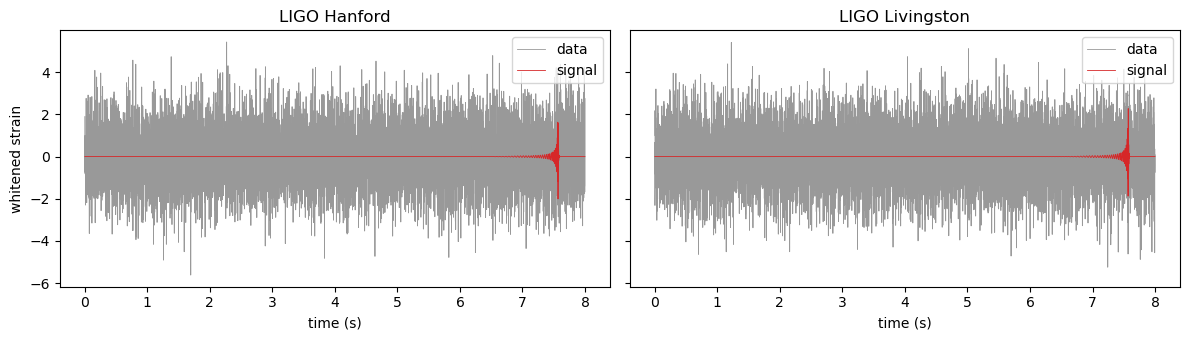

In [3]:
noise_alone, _, _ = simulate(0.0, seed=13)
n = int(2 * fmax * T)
t = np.arange(n) / (2 * fmax)
sigma = np.sqrt(signal['sig2'] / 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, I, name in zip(axes, 'HL', ('LIGO Hanford', 'LIGO Livingston')):
    for d, color, label in ((signal['d_' + I][0], '0.6', 'data'), (signal['d_' + I][0] - noise_alone['d_' + I][0], 'C3', 'signal')):
        D = np.zeros(n // 2 + 1, complex)
        D[signal['nu']] = d / sigma
        ax.plot(t, np.fft.irfft(D, n) * np.sqrt(n), color=color, lw=0.6, label=label)
    ax.set_title(name)
    ax.set_xlabel('time (s)')
    ax.legend(loc='upper right')
axes[0].set_ylabel('whitened strain')
plt.tight_layout()
plt.show()

## Analyze

The template bank has 120 detector-frame total masses between 20 and 200 solar masses. For every template the code filters the data of the two detectors and reads the tables over the arrival times and the delays between the detectors. `pe_redshift` turns the result into the likelihood ratio on a grid of (m1, z) and into its average over the prior, the Bayes factor ln B.

In [4]:
start = time.time()
store = search.load_redshift_store('../tables/redshift', mmap=True)
bank = search.mass_bank(np.geomspace(20, 200, 120), segments, 'cpu')
print('tables mapped and bank built in %.0f s' % (time.time() - start))

start = time.time()
result = search.pe_redshift(segments, bank, store, mdet_range=(20.0, 200.0))     # prior on M_det = the range of the bank
seconds = time.time() - start
print('2 segments in %.0f s on the CPU' % seconds)
print('ln B, segment with the merger: %.2f' % result['ln_b'][0])
print('ln B, noise only:              %.2f' % result['ln_b'][1])

tables mapped and bank built in 0 s


2 segments in 5 s on the CPU
ln B, segment with the merger: 6.31
ln B, noise only:              -0.01


## Plot

The posterior is the likelihood ratio times the prior of ln B, uniform in detector-frame mass and uniform in Euclidean volume, which is proportional to D² in luminosity distance D.

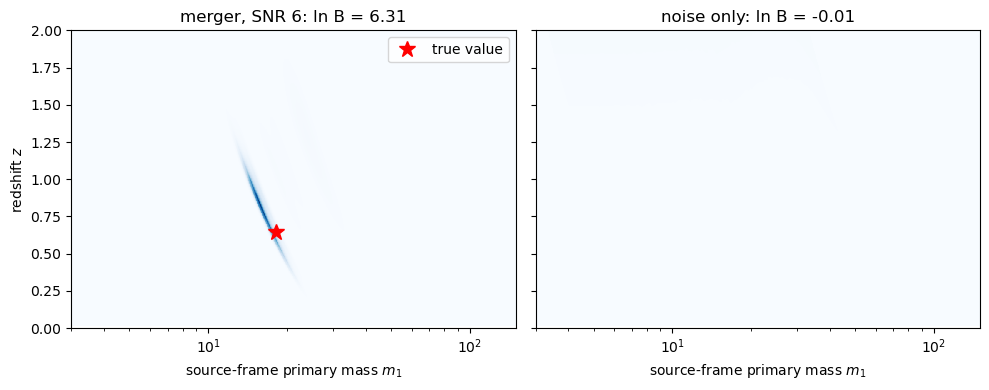

In [5]:
m1, z = result['m1'], result['z']
DL = Planck18.luminosity_distance(z).value
prior = (1 + z) * DL ** 2 * np.gradient(DL, z)
inside = (2 * m1[:, None] * (1 + z[None, :]) >= 20) & (2 * m1[:, None] * (1 + z[None, :]) <= 200)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, row, title in zip(axes, (0, 1), ('merger, SNR %.0f' % snr[0], 'noise only')):
    lp = np.where(inside, result['ln_lambda'][row] + np.log(prior)[None, :], -np.inf)
    post = np.exp(lp - lp[np.isfinite(lp)].max())
    ax.pcolormesh(m1, z, post.T, shading='auto', cmap='Blues')
    ax.set_xscale('log')
    ax.set_xlabel('source-frame primary mass $m_1$')
    ax.set_title('%s: ln B = %.2f' % (title, result['ln_b'][row]))
axes[0].plot(m1_true, z_true, 'r*', ms=12, label='true value')
axes[0].legend(loc='upper right')
axes[0].set_ylabel('redshift $z$')
axes[0].set_ylim(0, 2)
plt.tight_layout()
plt.show()